In [ ]:
import pandas as pd
import math
import numpy as np
import pydotplus as pydot
from graphviz import Digraph
import copy
import csv
from google.colab import files

In [ ]:
class helper:
  def __init__(self):
    self.i= 0
  def datasetListMergeMinus(self, dataset, subset):
    wholeData = 1
    for m in dataset:
      if not m.equals(subset):
        if type(wholeData) is int:
          wholeData = m
        else:
          wholeData = wholeData.append(m)
    return wholeData
  def multiDimStrToUpper(self, string):
    nstring = []
    for strns in string:
      nstring.append([x.upper() for x in strns])
    return nstring
  def multiDimStrToLower(self, string):
    nstring = []
    for strns in string:
      nstring.append([x.lower() for x in strns])
    return nstring
  def oneDimStrToLower(self, string):
    nstring = []
    for i in range(0, len(string)):
      nstring.append(string[i].lower())
    return nstring
  def grabEventsFromHeader(self, header):
    evs = []
    c = 0
    for ev in header:
      if c > 0:
        try:
          num = int(ev)
        except:
          evs.append(ev)
      c = c + 1
    return evs

  def rowIsFirst(self, row, activities, headers):
    foundValues = [];
    for i in range(0,len(headers)):
      val = headers[i]
      if row[val] in activities:
        foundValues.append(row[val])
    if (len(foundValues) == 0):
      return True
    return False

  def rowIsLast(self, row, evName):
    rowEv = row.idxmax()
    try:
      if rowEv.lower() == evName.lower():
        return True
    except:
      return False
    return False

  def divideMatrix(self, matrix):
    headers = list(matrix.columns.values)
    leftHeaders = []
    rightHeaders = []
    for i in range(0,len(headers)):
      ev = headers[i]
      try:
          num = int(ev)
          leftHeaders.append(ev)
      except:
          rightHeaders.append(ev)
    leftData = matrix[leftHeaders]
    rightData = matrix[rightHeaders]
    return [leftData, rightData]

In [ ]:
class resultGraphing:
  def __init__(self):
    self.i= 0

  def decomposeResult(self, results):
    helper_ = helper()
    headers = list(results.columns.values)
    events = helper_.grabEventsFromHeader(headers)
    matrices = []
    matricesLeft = []
    lastIndex = 0
    totalBegin = 0
    ind = 0
    newMatrix = helper_.divideMatrix(results)
    for index, row in newMatrix[1].iterrows():
      ind = index
      rowIsLast = helper_.rowIsLast(row, "end")
      if rowIsLast:
        sequenceList = newMatrix[1].iloc[lastIndex:index+1, :]
        sequenceListLeft = newMatrix[0].iloc[lastIndex:index+1, :]
        matrices.append(sequenceList)
        matricesLeft.append(sequenceListLeft)
        lastIndex = index + 1
    return matrices, matricesLeft

  def rowIsAnewSequence(self, row):
    try:
      return math.isnan(row["1"])
    except:
      return False

  def linkAndProbability(self, matrices):
    links = []
    probabilities = []
    sequences = []
    uniqueEvs = []
    for i in range(0,len(matrices)):
      thisMatrix = matrices[i]
      lastEvent = "Start"
      sequence = []
      for index, row in thisMatrix.iterrows():
        row = pd.to_numeric(row)
        #print(row) # prints the rows
        evName = row.idxmax(axis=1) # picks event with the highest probability
        link = lastEvent + "<-->" + evName
        sequence.append(evName)
        if link not in links:
          if lastEvent != evName:
            links.append(link)
            prob = row[evName] #g
            probabilities.append(prob)
        lastEvent = evName
      # The Last element is End and undesirable
      sequence.pop()
      sequences.append(sequence)
    return links, probabilities, sequences

  def linkAndProbabilities(self, seqs, probs):
    links = []
    probabilities = []
    sequences = []
    uniqueEvs = []
    orphanLog = []
    pointedToLog = []
    allowedActivities = probs[0].columns.values
    for i in range(0,len(seqs)):
      thisMatrix = probs[i]
      lastEvent = "Start"
      sequence = []
      completeSequence = seqs[i].iloc[-1]
      for j in range(1, len(completeSequence)):
        if completeSequence[j] in allowedActivities:
          evName = completeSequence[j]
          sequence.append(evName)
          link = lastEvent + "<-->" + evName
          prob = probs[i][evName].max(axis=0)
          if link not in links:
            links.append(link)
            probabilities.append(prob)
          lastEvent = evName
        else:
          link = lastEvent + "<-->End"
          prob = 100
          if link not in links:
            links.append(link)
            probabilities.append(prob)
          lastEvent = "End"
          break
      sequences.append(sequence)
    return links, probabilities, sequences

  def manageTree(self, eventFrom, eventTo, orphanLog, pointedTo):
    if eventTo not in pointedTo:
      pointedTo.append(eventTo)
    if eventFrom not in pointedTo:
      if eventFrom not in orphanLog:
        orphanLog.append(eventFrom)
    else:
      if eventFrom in orphanLog:
        orphanLog.remove(eventFrom)
    return orphanLog, pointedTo

  def cleanUpTree(self, links, probs, orphans):
    counter = 0;
    for j in links:
      evs = j.split("<-->")
      if evs[0] in orphans:
        links.remove(j);
        probs.pop(counter)
      counter = counter + 1
    return links, probs

  def drawGraph(self, transitions, probabilities, transitions_ref, probabilities_ref):
    counter = 0
    G = Digraph('process_model', filename='graph_'+str(counter)+'.gv')
    G.attr(rankdir='TB', size='7,5')
    G.attr('node', shape='doublecircle', style="filled", fillcolor="grey")
    G.node('Start')
    G.node('END')
    G.attr('node', shape='box', style="bold")

    #Graph two
    G2 = Digraph('process_model', filename='graph2_'+str(counter)+'.gv')
    G2.attr(rankdir='TB', size='7,5')
    G2.attr('node', shape='doublecircle', style="filled", fillcolor="grey")
    G2.node('Start')
    G2.node('END')
    G2.attr('node', shape='box', style="bold")
    for i in range(0,len(transitions)):

      try:
        tIndex = transitions_ref.index(transitions[i])
        driftedProb = probabilities_ref[tIndex]
      except:
        driftedProb = 0
      fromto = transitions[i].split("<-->")
      if (fromto[0].lower() == "start" and fromto[1].lower() == "end"):
        continue
      if (fromto[0].lower() != "end"):
        G.attr('edge', style="bold", color='black', penwidth='3.0', label=str(probabilities[i]))
        try:
          if probabilities[i] > driftedProb:
            diff = abs(driftedProb - probabilities[i])
            percentageSim = ((1- diff/probabilities[i]))
          else:
            percentageSim = 1
        except ZeroDivisionError:
           percentageSim = 0
        G.edge(fromto[0], fromto[1])
        if percentageSim > 0.8:
          G2.attr('edge', style="bold", color='black', penwidth='3.0', label=str(driftedProb))
          G2.edge(fromto[0], fromto[1])
        else:
          G2.attr('edge', style="dotted", color = 'black', penwidth='3.0', label=str(driftedProb))
          G2.edge(fromto[0], fromto[1])
    G.view()
    G2.view()
    return G, G2

  def getEventSequence(self, data, X_label, Y_label):
    currentX_label = ''
    sequences = []
    sequence = []
    for index, row in data.iterrows():
      if currentX_label == row[X_label]:
        sequence.append(row[Y_label])
      else:
        if len(sequence) > 1:
          sequences.append(sequence)
        sequence = []
        sequence.append(row[Y_label])
      currentX_label = row[X_label]
    sequences.append(sequence)
    return sequences

In [ ]:
start = 1
end = 5;
for i in range(start, end+5):
  diff = abs(i - end);
  print((1- diff/end))

In [ ]:
resultGraphing_ = resultGraphing()

In [ ]:
result = pd.read_csv('referenceLog_1.csv')
result_alt = pd.read_csv('detectionLog_1.csv')

In [ ]:
probs, seqs = resultGraphing_.decomposeResult(result)
probs_a, seqs_a = resultGraphing_.decomposeResult(result_alt)

TypeError: ignored

In [ ]:
link, probabilities, sequences = resultGraphing_.linkAndProbability(probs)

In [ ]:
link_a, probabilities_a, sequences_a = resultGraphing_.linkAndProbability(probs_a)

In [ ]:
probabilities_a

[99.0,
 94.0,
 94.0,
 97.0,
 52.0,
 97.0,
 98.0,
 100.0,
 99.0,
 39.0,
 99.0,
 99.0,
 99.0,
 99.0,
 99.0,
 99.0,
 63.0,
 98.0,
 99.0,
 98.0,
 99.0,
 41.0,
 99.0,
 49.0,
 99.0,
 60.0,
 99.0,
 65.0,
 98.0,
 98.0,
 97.0,
 99.0]

In [ ]:
g1, g2 = resultGraphing_.drawGraph(link, probabilities,link_a, probabilities_a)

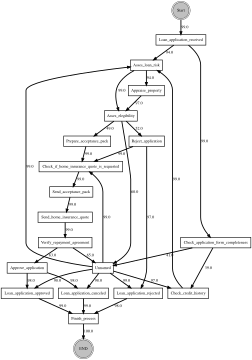

In [ ]:
g1

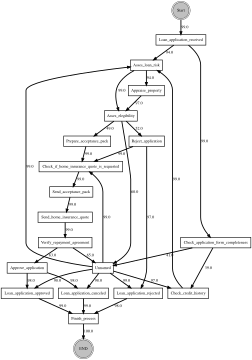

In [ ]:
g2